# (b) & (c)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
from tabulate import tabulate
from sklearn.linear_model import LinearRegression

In [6]:
weekly_returns = pd.read_excel('D:\MG\！CUHKSZ\~！大二 下\FIN3080\Assignments\A3\TRD_Week_1.xlsx', header=0, skiprows=[1, 2], dtype={'Stkcd': str})
weekly_returns1 = pd.read_excel('D:\MG\！CUHKSZ\~！大二 下\FIN3080\Assignments\A3\TRD_Week_2.xlsx', header=0, skiprows=[1, 2], dtype={'Stkcd': str})
weekly_returns = pd.concat([weekly_returns, weekly_returns1], ignore_index=True)
weekly_returns = weekly_returns[weekly_returns['Trdwnt'] < '2023-01'].reset_index(drop=True)

print(weekly_returns.head())

<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:2: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:2: SyntaxWarning: invalid escape sequence '\M'
C:\Users\19927\AppData\Local\Temp\ipykernel_3644\795127205.py:1: SyntaxWarning: invalid escape sequence '\M'
  weekly_returns = pd.read_excel('D:\MG\！CUHKSZ\~！大二 下\FIN3080\Assignments\A3\TRD_Week_1.xlsx', header=0, skiprows=[1, 2], dtype={'Stkcd': str})
C:\Users\19927\AppData\Local\Temp\ipykernel_3644\795127205.py:2: SyntaxWarning: invalid escape sequence '\M'
  weekly_returns1 = pd.read_excel('D:\MG\！CUHKSZ\~！大二 下\FIN3080\Assignments\A3\TRD_Week_2.xlsx', header=0, skiprows=[1, 2], dtype={'Stkcd': str})


    Stkcd   Trdwnt    Wretnd
0  000001  2017-01  0.003297
1  000001  2017-02  0.003286
2  000001  2017-03  0.006550
3  000001  2017-04  0.011931
4  000001  2017-05 -0.007503


In [7]:
df= pd.read_excel('D:\MG\！CUHKSZ\~！大二 下\FIN3080\Assignments\A3\weekly_risk_free_rate.xlsx', sheet_name='Sheet1')
df['trading_date_yw'] = pd.to_datetime(df['trading_date_yw'])
df.set_index('trading_date_yw', inplace=True)
df['Trdwnt'] = df.index.to_period('W').strftime('%Y-%U')

print(df.head())

                 risk_free_return   Trdwnt
trading_date_yw                           
2017-01-01               0.000571  2017-01
2017-01-08               0.000738  2017-02
2017-01-15               0.000543  2017-03
2017-01-22               0.000774  2017-04
2017-01-29               0.000802  2017-05


<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
C:\Users\19927\AppData\Local\Temp\ipykernel_3644\3473678408.py:1: SyntaxWarning: invalid escape sequence '\M'
  df= pd.read_excel('D:\MG\！CUHKSZ\~！大二 下\FIN3080\Assignments\A3\weekly_risk_free_rate.xlsx', sheet_name='Sheet1')


In [8]:
final_df= pd.merge(weekly_returns,df, on = 'Trdwnt', how = 'left')

print(final_df.head())

    Stkcd   Trdwnt    Wretnd  risk_free_return
0  000001  2017-01  0.003297          0.000571
1  000001  2017-02  0.003286          0.000738
2  000001  2017-03  0.006550          0.000543
3  000001  2017-04  0.011931          0.000774
4  000001  2017-05 -0.007503          0.000802


In [9]:
market_returns = final_df.groupby('Trdwnt')['Wretnd'].mean().reset_index()
market_returns .rename(columns={'Wretnd': 'Market_Return'}, inplace=True)
final_df = pd.merge(final_df,market_returns , on='Trdwnt', how='left')

print(final_df.head())

    Stkcd   Trdwnt    Wretnd  risk_free_return  Market_Return
0  000001  2017-01  0.003297          0.000571       0.016611
1  000001  2017-02  0.003286          0.000738      -0.035048
2  000001  2017-03  0.006550          0.000543      -0.017417
3  000001  2017-04  0.011931          0.000774       0.019902
4  000001  2017-05 -0.007503          0.000802      -0.002530


In [10]:
final_df.sort_values(by=['Trdwnt'], inplace=True)

print(final_df.head())

         Stkcd   Trdwnt    Wretnd  risk_free_return  Market_Return
0       000001  2017-01  0.003297          0.000571       0.016611
13592   000062  2017-01 -0.029567          0.000571       0.016611
429664  300016  2017-01 -0.003790          0.000571       0.016611
818649  600555  2017-01  0.006400          0.000571       0.016611
429966  300017  2017-01  0.020705          0.000571       0.016611


# (d)

In [11]:
stocks_by_t = final_df.groupby('Trdwnt')['Stkcd'].apply(set)
stocks_in_all_t = set.intersection(*stocks_by_t)

print(f"共有 {len(stocks_in_all_t)} 支股票在所有 t 都出现过")

共有 1604 支股票在所有 t 都出现过


In [12]:
dates = final_df['Trdwnt'].unique().tolist()
end_date = dates[100]
df_window1 = final_df[final_df['Trdwnt'] <= end_date]
stocks = df_window1['Stkcd'].unique()

def calculate_individual_betas(df, window_size=100):
    """
    计算各个股票的beta值，使用前window_size个时间点的数据
    """
    dates = final_df['Trdwnt'].unique().tolist()
    end_date = dates[100]
    df_window1 = final_df[final_df['Trdwnt'] <= end_date]
    stocks = df_window1['Stkcd'].unique()
    # 存储每只股票的beta值
    betas = []
    
    for stock in stocks:
        # 获取该股票的数据
        stock_data = df[df['Stkcd'] == stock].copy()
        
        # 确保数据按时间排序
        stock_data.sort_values('Trdwnt', inplace=True)
        
        # 如果数据点不足window_size，则使用所有可用数据
        if len(stock_data) < window_size:
            actual_window = len(stock_data)
        else:
            actual_window = window_size
            
        # 使用前actual_window个数据点
        regression_data = stock_data.head(actual_window)
        
        # 如果数据不足以进行回归，则跳过
        if len(regression_data) < 10:  # 至少需要10个点才能进行有意义的回归
            continue
            
        # 根据图2显示的模型 r_i,t = α_i + β_i * r_m,t + ε_i 进行回归
        X = regression_data['Market_Return'].values.reshape(-1, 1)
        X = sm.add_constant(X)  # 添加常数项
        y = regression_data['Wretnd'].values
        
        # 使用OLS模型进行回归
        model = sm.OLS(y, X).fit()
        
        # 获取beta值（系数的第二个元素）
        beta = model.params[1]
        
        betas.append({
            'Stkcd': stock,
            'T1_beta': beta
        })
    
    return pd.DataFrame(betas)
individual_beta = calculate_individual_betas(final_df, window_size=100)

In [13]:
print(individual_beta.head())

    Stkcd   T1_beta
0  000001  0.264194
1  000062  1.076232
2  300016  1.274483
3  600555  1.162041
4  300017  1.280862


In [14]:
final_df = pd.merge(final_df, individual_beta, on='Stkcd', how='left')
final_df['T1_beta'] = final_df['T1_beta'].astype(float)

print(final_df.head())

    Stkcd   Trdwnt    Wretnd  risk_free_return  Market_Return   T1_beta
0  000001  2017-01  0.003297          0.000571       0.016611  0.264194
1  000062  2017-01 -0.029567          0.000571       0.016611  1.076232
2  300016  2017-01 -0.003790          0.000571       0.016611  1.274483
3  600555  2017-01  0.006400          0.000571       0.016611  1.162041
4  300017  2017-01  0.020705          0.000571       0.016611  1.280862


In [15]:
individual_beta.isnull().sum()/ individual_beta.shape[0] * 100

Stkcd       0.000000
T1_beta    15.162556
dtype: float64

In [17]:
# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'Microsoft YaHei', 'WenQuanYi Micro Hei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = 'sans-serif'

df = final_df.copy()
df = df.dropna(subset=['T1_beta', 'Wretnd', 'Market_Return', 'risk_free_return'])
time_points = sorted(df['Trdwnt'].unique())
if len(time_points) >= 200:
    selected_times = time_points[101:201]
    selected_data = df[df['Trdwnt'].isin(selected_times)].copy()
else:
    print(f"警告：数据不足200个时间点，仅有{len(time_points)}个时间点。使用所有可用数据。")
    selected_data = df.copy()

In [18]:
# 按照beta值分成10组
# 先处理可能存在的NaN值
selected_data_with_beta = selected_data.dropna(subset=['T1_beta'])
selected_data_with_beta ['excess_return'] = selected_data_with_beta ['Wretnd'] - selected_data_with_beta ['risk_free_return']
selected_data_with_beta ['excess_market_return'] = selected_data_with_beta ['Market_Return'] - selected_data_with_beta ['risk_free_return']

selected_data_with_beta['beta_group'] = pd.qcut(selected_data_with_beta['T1_beta'], 
                                              q=10, 
                                              labels=False) + 1

In [19]:
# 将分组信息以及超额收益率合并回原始DataFrame
selected_data = pd.merge(selected_data, 
                        selected_data_with_beta[['Stkcd', 'Trdwnt', 'beta_group', 'excess_return', 'excess_market_return']], 
                        on=['Stkcd', 'Trdwnt'], 
                        how='left')
# 计算每组的平均超额收益和超额市场收益
portfolio_data = selected_data_with_beta.groupby(['Trdwnt', 'beta_group']).agg({
    'excess_return': 'mean',
    'excess_market_return': 'mean'
}).reset_index()

In [20]:
# 存储回归结果
portfolio_betas = []
portfolio_alphas = []
portfolio_r2 = []
alpha_t_values = []
beta_t_values = []
alpha_p_values = []
beta_p_values = []
group_numbers = []

for group in range(1, 11):
    group_data = portfolio_data[portfolio_data['beta_group'] == group]
    
    if len(group_data) == 0:
        print(f"警告：组合 {group} 没有数据，跳过")
        continue
    
    group_numbers.append(group)
    
    # 准备回归数据
    X = group_data['excess_market_return'].values.reshape(-1, 1)
    y = group_data['excess_return'].values
    
    # 回归模型
    model = LinearRegression()
    model.fit(X, y)
    
    # 保存基本结果
    beta = model.coef_[0]
    alpha = model.intercept_
    r2 = model.score(X, y)
    
    portfolio_betas.append(beta)
    portfolio_alphas.append(alpha)
    portfolio_r2.append(r2)
    
    # 计算t值和p值
    n = len(X)
    k = 1  # 解释变量数量
    
    # 得到预测值
    y_pred = model.predict(X)
    
    # 计算残差
    residuals = y - y_pred
    
    # 残差平方和
    sse = np.sum(residuals**2)
    
    # 回归自由度调整后的标准误
    se = np.sqrt(sse / (n - k - 1))
    
    # X的方差
    x_mean = np.mean(X)
    x_var = np.sum((X - x_mean)**2)
    
    # 计算beta的标准误
    beta_se = se / np.sqrt(x_var)
    
    # 计算alpha的标准误
    alpha_se = se * np.sqrt(1/n + np.mean(X)**2/x_var)
    
    # 计算t值
    beta_t = beta / beta_se
    alpha_t = alpha / alpha_se
    
    # 计算p值 (双尾检验)
    beta_p = 2 * (1 - stats.t.cdf(abs(beta_t), df=n-k-1))
    alpha_p = 2 * (1 - stats.t.cdf(abs(alpha_t), df=n-k-1))
    
    # 保存t值和p值
    alpha_t_values.append(alpha_t)
    beta_t_values.append(beta_t)
    alpha_p_values.append(alpha_p)
    beta_p_values.append(beta_p)

In [21]:
# 创建回归结果DataFrame
results = pd.DataFrame({
    "beta_group": group_numbers,
    "组合名称": [f"组合 {i}" for i in group_numbers],
    "α_p": portfolio_alphas,
    "α_p的t值": alpha_t_values,
    "显著性": alpha_p_values,
    "β_p": portfolio_betas,
    "β_p的t值": beta_t_values,
    "β_p显著性": beta_p_values,
    "R-squared": portfolio_r2
})

In [22]:
# 格式化p值显示
def format_p_value(p):
    if p < 2e-16:
        return "<2e-16"
    elif p < 0.0001:
        return f"{p:.2e}"
    else:
        return f"{p:.4f}"

# 应用格式化
results["显著性"] = results["显著性"].apply(lambda x: f"{x:.4f}")
results["β_p显著性"] = results["β_p显著性"].apply(format_p_value)

In [24]:
# 展示表格
print("Portfolio Beta分析结果:")
print(tabulate(results, headers='keys', tablefmt='pretty', floatfmt=".5f"))


Portfolio Beta分析结果:
+---+------------+----------+-------------------------+----------------------+--------+--------------------+--------------------+-----------+--------------------+
|   | beta_group | 组合名称 |           α_p           |       α_p的t值       | 显著性 |        β_p         |      β_p的t值      | β_p显著性 |     R-squared      |
+---+------------+----------+-------------------------+----------------------+--------+--------------------+--------------------+-----------+--------------------+
| 0 |     1      |  组合 1  | -0.0007355782294599738  |  -0.809422949287926  | 0.4202 | 0.7099253828744077 | 25.449111513990815 |  <2e-16   |  0.86857232800866  |
| 1 |     2      |  组合 2  | -0.00027404467166510134 | -0.4075328531557508  | 0.6845 | 0.8527100045347046 | 41.31006658724922  |  <2e-16   | 0.9456919773519832 |
| 2 |     3      |  组合 3  | -0.0001280350373492386  | -0.24604125549206785 | 0.8062 | 0.8840132414893899 | 55.34152802193001  |  <2e-16   | 0.9689940602863694 |
| 3 |     4      |  组合

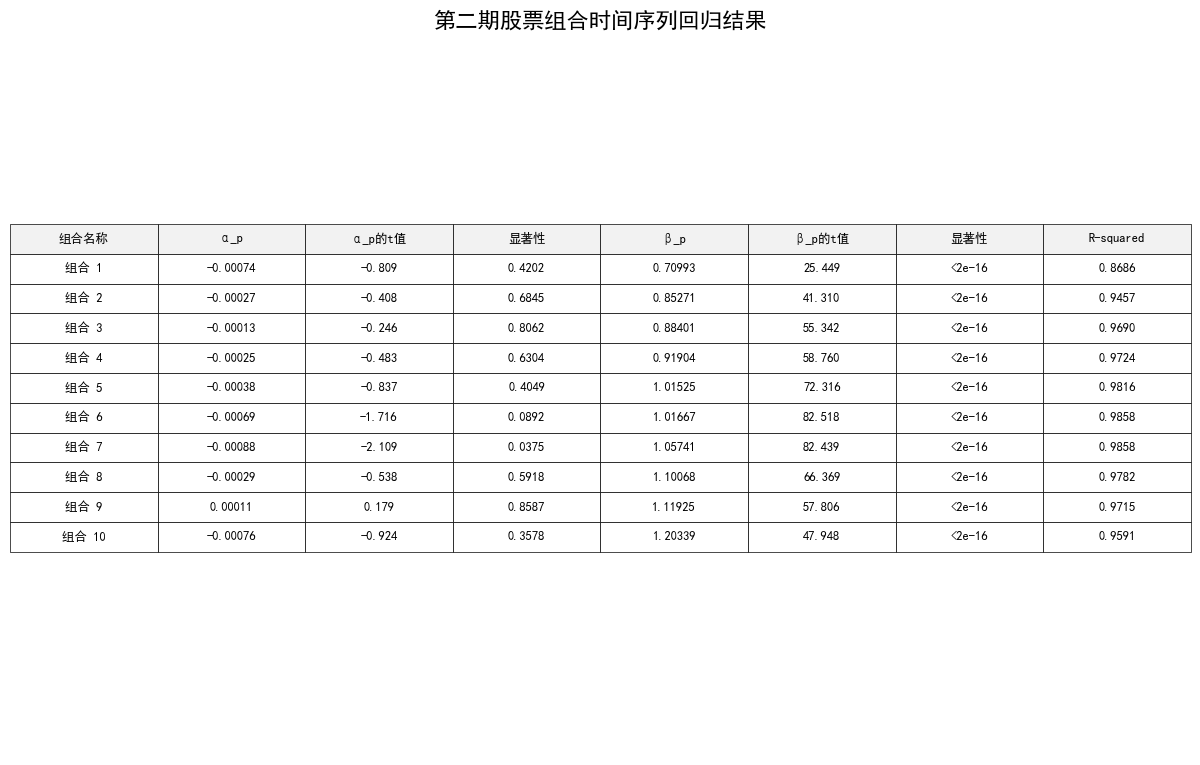

In [26]:
# 使用Matplotlib创建更美观的表格
fig, ax = plt.subplots(figsize=(12, 8))
ax.axis('tight')
ax.axis('off')

# 表格数据
cell_text = []
for i in range(len(results)):
    row = [results.iloc[i]["组合名称"],
           f"{results.iloc[i]['α_p']:.5f}",
           f"{results.iloc[i]['α_p的t值']:.3f}",
           results.iloc[i]['显著性'],
           f"{results.iloc[i]['β_p']:.5f}",
           f"{results.iloc[i]['β_p的t值']:.3f}",
           results.iloc[i]['β_p显著性'],
           f"{results.iloc[i]['R-squared']:.4f}"]
    cell_text.append(row)
    
# 创建表格
table = ax.table(
    cellText=cell_text,
    colLabels=["组合名称", "α_p", "α_p的t值", "显著性", "β_p", "β_p的t值", "显著性", "R-squared"],
    loc='center',
    cellLoc='center',
    colColours=["#f2f2f2"] * 8
)

# 设置表格样式
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)

# 绘制表格外边框
for key, cell in table.get_celld().items():
    cell.set_linewidth(0.5)
    
# 设置标题
plt.suptitle('第二期股票组合时间序列回归结果', fontsize=16, y=0.95)

# 调整边距
plt.tight_layout()

# 保存图片
plt.savefig('portfolio_regression_results.png', dpi=300, bbox_inches='tight')

# 显示图表
plt.show()

In [28]:
# 创建一个映射字典，将beta_group映射到相应的portfolio_beta
portfolio_beta_map = dict(zip(results['beta_group'], results['β_p']))

# 在selected_data中创建portfolio_beta列
selected_data['portfolio_beta'] = selected_data['beta_group'].map(portfolio_beta_map)

# 将portfolio_beta合并回final_df
# 先确保我们只从selected_data中取需要的列
portfolio_beta_data = selected_data[['Stkcd', 'Trdwnt', 'portfolio_beta','beta_group']].copy()
# Create dictionaries for mapping
beta_map = portfolio_beta_data.set_index('Stkcd')['portfolio_beta'].to_dict()
group_map = portfolio_beta_data.set_index('Stkcd')['beta_group'].to_dict()

# Apply the mappings
df = final_df.copy()
df['portfolio_beta'] = df['Stkcd'].map(beta_map)
df['beta_group'] = df['Stkcd'].map(group_map)

In [29]:
df = df.drop(columns=['Market_Return'], inplace=False)
df.dropna(subset=['portfolio_beta'], inplace=True)

print(df.head())

    Stkcd   Trdwnt    Wretnd  risk_free_return   T1_beta  portfolio_beta  \
0  000001  2017-01  0.003297          0.000571  0.264194        0.709925   
1  000062  2017-01 -0.029567          0.000571  1.076232        1.057410   
2  300016  2017-01 -0.003790          0.000571  1.274483        1.119250   
3  600555  2017-01  0.006400          0.000571  1.162041        1.100683   
4  300017  2017-01  0.020705          0.000571  1.280862        1.119250   

   beta_group  
0         1.0  
1         7.0  
2         9.0  
3         8.0  
4         9.0  


In [30]:
len(sorted(df['Trdwnt'].unique()))

308

---

In [31]:
# 设置中文字体支持
df['beta_group'] = df['beta_group'].astype(int)
# df = final_df.copy()
df = df.dropna(subset=['portfolio_beta', 'Wretnd','risk_free_return'])
time_points = sorted(df['Trdwnt'].unique())

In [32]:
# 取第200期之后的所有日期
if len(time_points) >= 200:
    selected_times = time_points[200:]  # 200期之后的所有日期
    selected_data = df[df['Trdwnt'].isin(selected_times)].copy()
    print(f"使用第200期之后的数据，包含{len(selected_times)}个时间点")
else:
    print(f"警告：数据不足200个时间点，仅有{len(time_points)}个时间点。使用所有可用数据。")
    selected_data = df.copy()

使用第200期之后的数据，包含104个时间点


In [33]:
# 计算每个时间点每个组合的平均超额收益
# 根据portfolio_beta进行排序（剔除空值）
valid_data = selected_data.dropna(subset=['portfolio_beta','beta_group'])

In [35]:
# 将计算出的市场均值合并回原数据
valid_data['excess_return'] = valid_data['Wretnd'] - valid_data['risk_free_return']
valid_data['excess_market_return'] = valid_data['Wretnd'] - valid_data['risk_free_return']

In [36]:
group_returns = valid_data.groupby('beta_group')['excess_return'].mean().reset_index()

group_betas = valid_data.groupby('beta_group')['portfolio_beta'].first().reset_index()

cross_sectional_data = pd.merge(group_returns, group_betas, on='beta_group', how='inner')

In [37]:
# 横截面回归: r_p - r_f = γ_0 + γ_1*β_p + ε_p
X = cross_sectional_data['portfolio_beta'].values.reshape(-1, 1)
y = cross_sectional_data['excess_return'].values

model = LinearRegression()
model.fit(X, y)

# 获取回归系数
gamma_0 = model.intercept_
gamma_1 = model.coef_[0]
r2 = model.score(X, y)

# 计算标准误差和t值
n = len(X)
k = 1  # 解释变量数量
y_pred = model.predict(X)
residuals = y - y_pred
sse = np.sum(residuals**2)
se = np.sqrt(sse / (n - k - 1))

# X的方差
x_mean = np.mean(X)
x_var = np.sum((X - x_mean)**2)

# 计算beta的标准误
gamma_1_se = se / np.sqrt(x_var)

# 计算alpha的标准误
gamma_0_se = se * np.sqrt(1/n + np.mean(X)**2/x_var)

# 计算t值
gamma_0_t = gamma_0 / gamma_0_se
gamma_1_t = gamma_1 / gamma_1_se

# 计算p值 (双尾检验)
gamma_0_p = 2 * (1 - stats.t.cdf(abs(gamma_0_t), df=n-k-1))
gamma_1_p = 2 * (1 - stats.t.cdf(abs(gamma_1_t), df=n-k-1))

# 计算F统计量
f_stat = (r2 / k) / ((1 - r2) / (n - k - 1))
f_p = 1 - stats.f.cdf(f_stat, k, n - k - 1)

C:\Users\19927\AppData\Local\Temp\ipykernel_3644\671983836.py:44: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) SimHei.
  plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')
C:\Users\19927\AppData\Local\Temp\ipykernel_3644\671983836.py:44: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) SimHei.
  plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')
C:\Users\19927\AppData\Local\Temp\ipykernel_3644\671983836.py:44: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')
C:\Users\19927\AppData\Local\Temp\ipykernel_3644\671983836.py:82: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()



横截面回归结果:
γ₀ = 0.0004, t值 = 0.8214, p值 = 0.4352
γ₁ = 0.0005, t值 = 1.0303, p值 = 0.3330
R² = 0.1171
F检验值 = 1.0616, p值 = 0.333000


C:\Users\19927\AppData\Local\Temp\ipykernel_3644\671983836.py:83: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.savefig('beta_vs_excess_return.png', dpi=300)
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


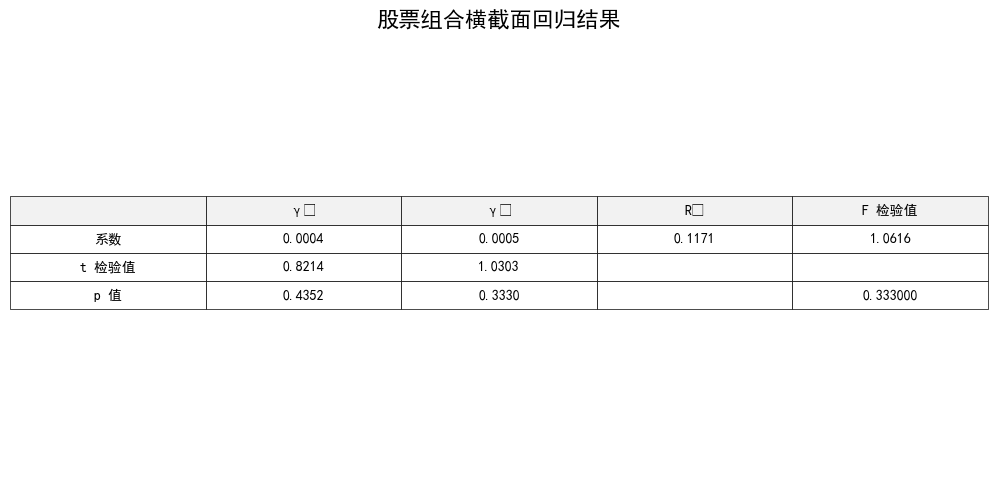

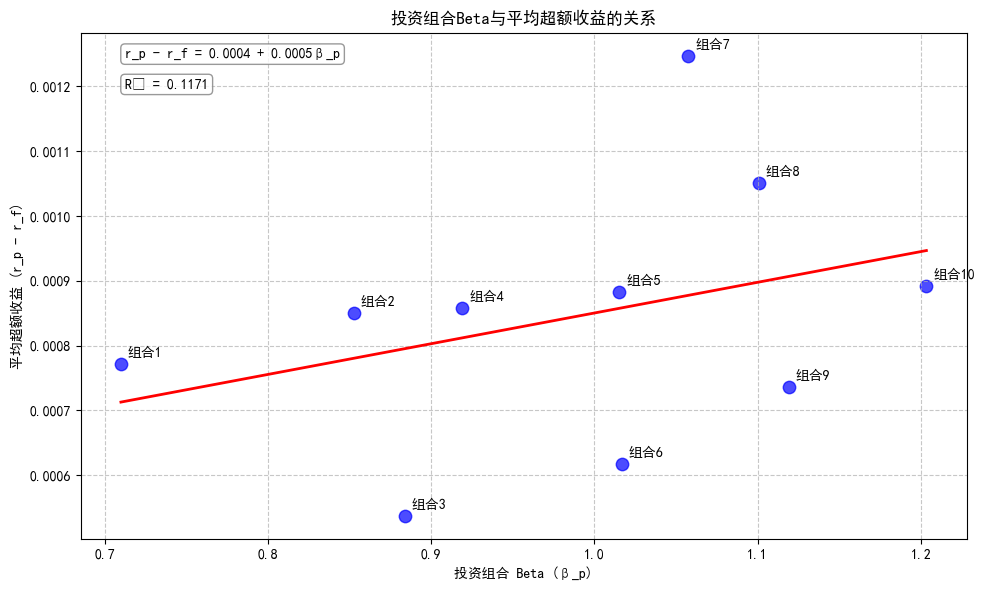

In [38]:
# 创建回归结果表格
results_table = {
    "": ["系数", "t 检验值", "p 值"],
    "γ₀": [f"{gamma_0:.4f}", f"{gamma_0_t:.4f}", f"{gamma_0_p:.4f}"],
    "γ₁": [f"{gamma_1:.4f}", f"{gamma_1_t:.4f}", f"{gamma_1_p:.4f}"],
    "R²": [f"{r2:.4f}", "", ""],
    "F 检验值": [f"{f_stat:.4f}", "", f"{f_p:.6f}"]
}

# 使用matplotlib绘制表格
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('tight')
ax.axis('off')

# 创建表格
table = ax.table(
    cellText=[
        [results_table[""][0], results_table["γ₀"][0], results_table["γ₁"][0], results_table["R²"][0], results_table["F 检验值"][0]],
        [results_table[""][1], results_table["γ₀"][1], results_table["γ₁"][1], "", ""],
        [results_table[""][2], results_table["γ₀"][2], results_table["γ₁"][2], "", results_table["F 检验值"][2]]
    ],
    colLabels=["", "γ₀", "γ₁", "R²", "F 检验值"],
    loc='center',
    cellLoc='center',
    colColours=["#f2f2f2"] * 5
)

# 设置表格样式
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

# 绘制表格外边框
for key, cell in table.get_celld().items():
    cell.set_linewidth(0.5)
    
# 设置标题
plt.suptitle('股票组合横截面回归结果', fontsize=16, y=0.95)

# 调整边距
plt.tight_layout()

# 保存图片
plt.savefig('cross_sectional_regression_results.png', dpi=300, bbox_inches='tight')

# 打印结果
print("\n横截面回归结果:")
print(f"γ₀ = {gamma_0:.4f}, t值 = {gamma_0_t:.4f}, p值 = {gamma_0_p:.4f}")
print(f"γ₁ = {gamma_1:.4f}, t值 = {gamma_1_t:.4f}, p值 = {gamma_1_p:.4f}")
print(f"R² = {r2:.4f}")
print(f"F检验值 = {f_stat:.4f}, p值 = {f_p:.6f}")

# 可视化结果：超额收益与portfolio_beta的关系
plt.figure(figsize=(10, 6))
plt.scatter(cross_sectional_data['portfolio_beta'], cross_sectional_data['excess_return'], 
            c='blue', alpha=0.7, s=80)

# 添加回归线
beta_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(beta_range, model.predict(beta_range), 'r-', linewidth=2)

# 在图上标注回归方程
equation = f"r_p - r_f = {gamma_0:.4f} + {gamma_1:.4f}β_p"
plt.annotate(equation, xy=(0.05, 0.95), xycoords='axes fraction', 
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

# 在图上标注R²值
r2_text = f"R² = {r2:.4f}"
plt.annotate(r2_text, xy=(0.05, 0.89), xycoords='axes fraction',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

# 标注数据点
for i, row in cross_sectional_data.iterrows():
    plt.annotate(f"组合{int(row['beta_group'])}", 
                xy=(row['portfolio_beta'], row['excess_return']),
                xytext=(5, 5), textcoords='offset points')

plt.xlabel('投资组合 Beta (β_p)')
plt.ylabel('平均超额收益 (r_p - r_f)')
plt.title('投资组合Beta与平均超额收益的关系')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('beta_vs_excess_return.png', dpi=300)
plt.show()